In [33]:
import random
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
tf.keras.utils.set_random_seed(SEED)


In [34]:
BATCH_SIZE = 32
IMAGE_SIZE = 256
CHANNELS = 3
EPOCHS = 50
TRAIN_SPLIT = 0.8
VAL_SPLIT = 0.1
DATASET_DIR = Path("PlantVillage")
MODEL_PATH = Path("Models") / "1.keras"


In [35]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp"}
class_names = [
    "Potato___Early_blight",
    "Potato___Late_blight",
    "Potato___healthy",
]
class_dirs = [DATASET_DIR / class_name for class_name in class_names]
if any(not class_dir.is_dir() for class_dir in class_dirs):
    raise FileNotFoundError(f"Expected class folders: {class_dirs}")
if len(class_names) != 3:
    raise ValueError(f"Expected 3 class folders, found {len(class_names)}: {class_names}")

split_paths = {"train": [], "validation": [], "test": []}
split_labels = {"train": [], "validation": [], "test": []}
for class_index, class_dir in enumerate(class_dirs):
    files = sorted(
        path for path in class_dir.iterdir()
        if path.is_file() and path.suffix.lower() in IMAGE_EXTENSIONS
    )
    random.Random(SEED + class_index).shuffle(files)
    train_end = int(len(files) * TRAIN_SPLIT)
    validation_end = train_end + int(len(files) * VAL_SPLIT)
    if min(train_end, validation_end - train_end, len(files) - validation_end) < 1:
        raise ValueError(f"Not enough images to split class {class_dir.name} into all sets")

    for split, split_files in (
        ("train", files[:train_end]),
        ("validation", files[train_end:validation_end]),
        ("test", files[validation_end:]),
    ):
        split_paths[split].extend(str(path) for path in split_files)
        split_labels[split].extend([class_index] * len(split_files))


def make_dataset(split, shuffle=False):
    paths = split_paths[split]
    labels = split_labels[split]
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        dataset = dataset.shuffle(len(paths), seed=SEED)

    def load_image(path, label):
        image = tf.io.read_file(path)
        image = tf.io.decode_image(image, channels=CHANNELS, expand_animations=False)
        image.set_shape((None, None, CHANNELS))
        image = tf.image.resize(image, (IMAGE_SIZE, IMAGE_SIZE))
        return image, label

    return (
        dataset.map(load_image, num_parallel_calls=tf.data.AUTOTUNE)
        .batch(BATCH_SIZE)
        .prefetch(tf.data.AUTOTUNE)
    )


train_ds = make_dataset("train", shuffle=True)
val_ds = make_dataset("validation")
test_ds = make_dataset("test")
dataset = train_ds

train_class_counts = np.bincount(split_labels["train"], minlength=len(class_names))
if np.any(train_class_counts == 0):
    raise ValueError("Every class must have training examples")
class_weights = {
    class_index: float(len(split_labels["train"]) / (len(class_names) * class_count))
    for class_index, class_count in enumerate(train_class_counts)
}

print("Classes:", class_names)
for split in ("train", "validation", "test"):
    counts = np.bincount(split_labels[split], minlength=len(class_names))
    print(f"{split.title()} images:", len(split_labels[split]), "per class:", counts.tolist())
print("Training class weights:", class_weights)


Classes: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Train images: 1721 per class: [800, 800, 121]
Validation images: 215 per class: [100, 100, 15]
Test images: 216 per class: [100, 100, 16]
Training class weights: {0: 0.7170833333333333, 1: 0.7170833333333333, 2: 4.741046831955923}


In [36]:
print(class_names)

['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']


(32, 256, 256, 3)
[0 1 0 1 0 0 1 0 1 1 0 0 1 0 2 0 0 1 1 0 1 1 0 1 0 0 1 1 0 0 2 1]


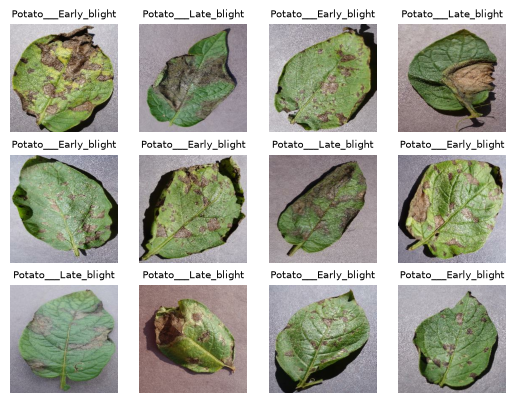

In [37]:
for image_batch, labels_batch in dataset.take(1):
    print(image_batch.shape)
    print(labels_batch.numpy())

    for i in range(12):
        ax = plt.subplot(3, 4, i + 1)

        plt.imshow(image_batch[i].numpy().astype("uint8"))
        label = labels_batch[i].numpy()
        plt.title(class_names[label], fontsize=7, pad=5)
        plt.axis("off")

In [38]:
import tensorflow as tf
from tensorflow.keras import layers

resize_and_rescale = tf.keras.Sequential([
    layers.Resizing(IMAGE_SIZE, IMAGE_SIZE),
    layers.Rescaling(1.0 / 255)
])

In [39]:
## DAta Augmentation
import tensorflow as tf
from tensorflow.keras import layers

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'),
    layers.RandomRotation(0.2)
])

In [40]:

import tensorflow as tf
from tensorflow.keras import layers, models

n_classes = len(class_names)

model = models.Sequential([
    layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS)),

    resize_and_rescale,
    data_augmentation,

    layers.Conv2D(32, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(n_classes, activation='softmax')
])

model.summary()


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ sequential_3 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_4 (Sequential)       │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 60, 60, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 30, 30, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 257,731 (1006.76 KB)

 Trainable params: 257,731 (1006.76 KB)

 Non-trainable params: 0 (0.00 B)

In [41]:
# The model is already built during instantiation via layers.Input, so we don't need to call model.build() manually.
# model.build(input_shape=input_shape)

In [42]:
model.compile(
    optimizer = 'adam',
    loss = tf.keras.losses.SparseCategoricalCrossentropy(from_logits=False),
    metrics= ['accuracy']
)

In [43]:
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.2,
        patience=3,
        min_lr=1e-6,
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    verbose=1,
    epochs=EPOCHS,
    class_weight=class_weights,
    callbacks=callbacks,
    shuffle=False,
)


Epoch 1/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 73s 1s/step - accuracy: 0.4503 - loss: 1.0590 - val_accuracy: 0.5953 - val_loss: 0.9941 - learning_rate: 0.0010
Epoch 2/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 79s 1s/step - accuracy: 0.4765 - loss: 0.9718 - val_accuracy: 0.5163 - val_loss: 0.7966 - learning_rate: 0.0010
Epoch 3/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 70s 1s/step - accuracy: 0.5456 - loss: 0.8019 - val_accuracy: 0.5581 - val_loss: 0.7715 - learning_rate: 0.0010
Epoch 4/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 67s 1s/step - accuracy: 0.6839 - loss: 0.5723 - val_accuracy: 0.5860 - val_loss: 0.9025 - learning_rate: 0.0010
Epoch 5/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.8222 - loss: 0.3796 - val_accuracy: 0.6465 - val_loss: 1.0749 - learning_rate: 0.0010
Epoch 6/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 60s 1s/step - accuracy: 0.8884 - loss: 0.2830 - val_accuracy: 0.8326 - val_loss: 0.4431 - learning_rate: 0.0010
Epoch 7/50
54/54 ━━━━━━━━━━━━━━━━━━━━ 56s 1s/step - accuracy: 0.8141 - loss: 0.4270 - val_accuracy: 

In [44]:
test_loss, test_accuracy = model.evaluate(test_ds, verbose=1)
print(f"Test loss: {test_loss:.4f}; test accuracy: {test_accuracy:.4f}")

y_true = np.concatenate([labels.numpy() for _, labels in test_ds])
y_pred = np.concatenate([
    np.argmax(model.predict(images, verbose=0), axis=1)
    for images, _ in test_ds
])
confusion_matrix = tf.math.confusion_matrix(
    y_true, y_pred, num_classes=len(class_names)
).numpy()
print("Class order:", class_names)
print("Confusion matrix (rows=true, columns=predicted):")
print(confusion_matrix)
for class_index, class_name in enumerate(class_names):
    class_recall = confusion_matrix[class_index, class_index] / confusion_matrix[class_index].sum()
    print(f"{class_name} recall: {class_recall:.3f}")


7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 268ms/step - accuracy: 0.8102 - loss: 0.4430
Test loss: 0.4430; test accuracy: 0.8102
Class order: ['Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy']
Confusion matrix (rows=true, columns=predicted):
[[92  5  3]
 [ 8 67 25]
 [ 0  0 16]]
Potato___Early_blight recall: 0.920
Potato___Late_blight recall: 0.670
Potato___healthy recall: 1.000


In [46]:
history.history['accuracy']

[0.4503195881843567,
 0.47646716237068176,
 0.5456129908561707,
 0.6839047074317932,
 0.8221964240074158,
 0.8884369730949402,
 0.8140615820884705,
 0.8942475318908691,
 0.9192330241203308,
 0.959907054901123,
 0.9575827717781067,
 0.9662986397743225,
 0.9692039489746094,
 0.9697850346565247]

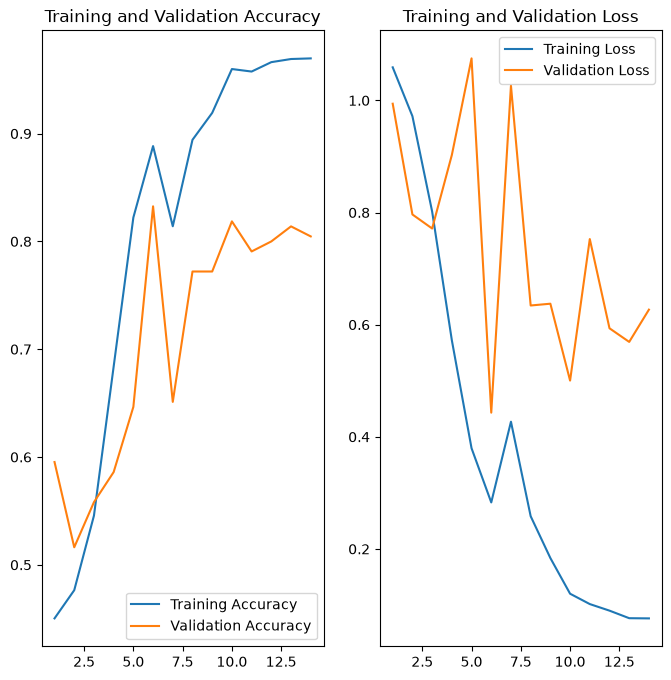

In [47]:
epochs_ran = range(1, len(history.history["accuracy"]) + 1)
plt.figure(figsize=(8, 8))
plt.subplot(1, 2, 1)
plt.plot(epochs_ran, history.history["accuracy"], label="Training Accuracy")
plt.plot(epochs_ran, history.history["val_accuracy"], label="Validation Accuracy")
plt.legend(loc="lower right")
plt.title("Training and Validation Accuracy")

plt.subplot(1, 2, 2)
plt.plot(epochs_ran, history.history["loss"], label="Training Loss")
plt.plot(epochs_ran, history.history["val_loss"], label="Validation Loss")
plt.legend(loc="upper right")
plt.title("Training and Validation Loss")
plt.show()


In [48]:
def predict(model, img):
    img_array = tf.keras.preprocessing.image.img_to_array(
        img.numpy()
    )
    img_array = tf.expand_dims(img_array, 0)

    predictions = model.predict(img_array, verbose=0)

    predicted_class = class_names[np.argmax(predictions[0])]
    confidence = round(float(np.max(predictions[0])) * 100, 2)

    print("All class scores:", predictions[0])

    return predicted_class, confidence

All class scores: [9.9967337e-01 3.2664690e-04 1.9707271e-09]
All class scores: [0.6553088  0.32626075 0.0184304 ]
All class scores: [9.995334e-01 4.666132e-04 4.794322e-09]
All class scores: [0.98220706 0.01612441 0.0016685 ]
All class scores: [0.88072914 0.08643487 0.03283593]
All class scores: [0.96006334 0.03884456 0.00109203]
All class scores: [9.953140e-01 4.685756e-03 2.645372e-07]
All class scores: [0.7641644  0.07485414 0.16098136]
All class scores: [9.9116546e-01 8.7929657e-03 4.1549636e-05]
All class scores: [9.8241258e-01 1.7443221e-02 1.4421700e-04]
All class scores: [9.994267e-01 5.732200e-04 9.841425e-08]
All class scores: [0.0364583  0.74459255 0.21894912]
All class scores: [0.1269547  0.48831856 0.38472673]
All class scores: [0.8834114  0.06965194 0.04693663]
All class scores: [9.8716974e-01 1.2762771e-02 6.7605419e-05]
All class scores: [9.9279916e-01 7.1510714e-03 4.9687289e-05]
All class scores: [9.9386013e-01 5.7309433e-03 4.0890771e-04]
All class scores: [9.998360

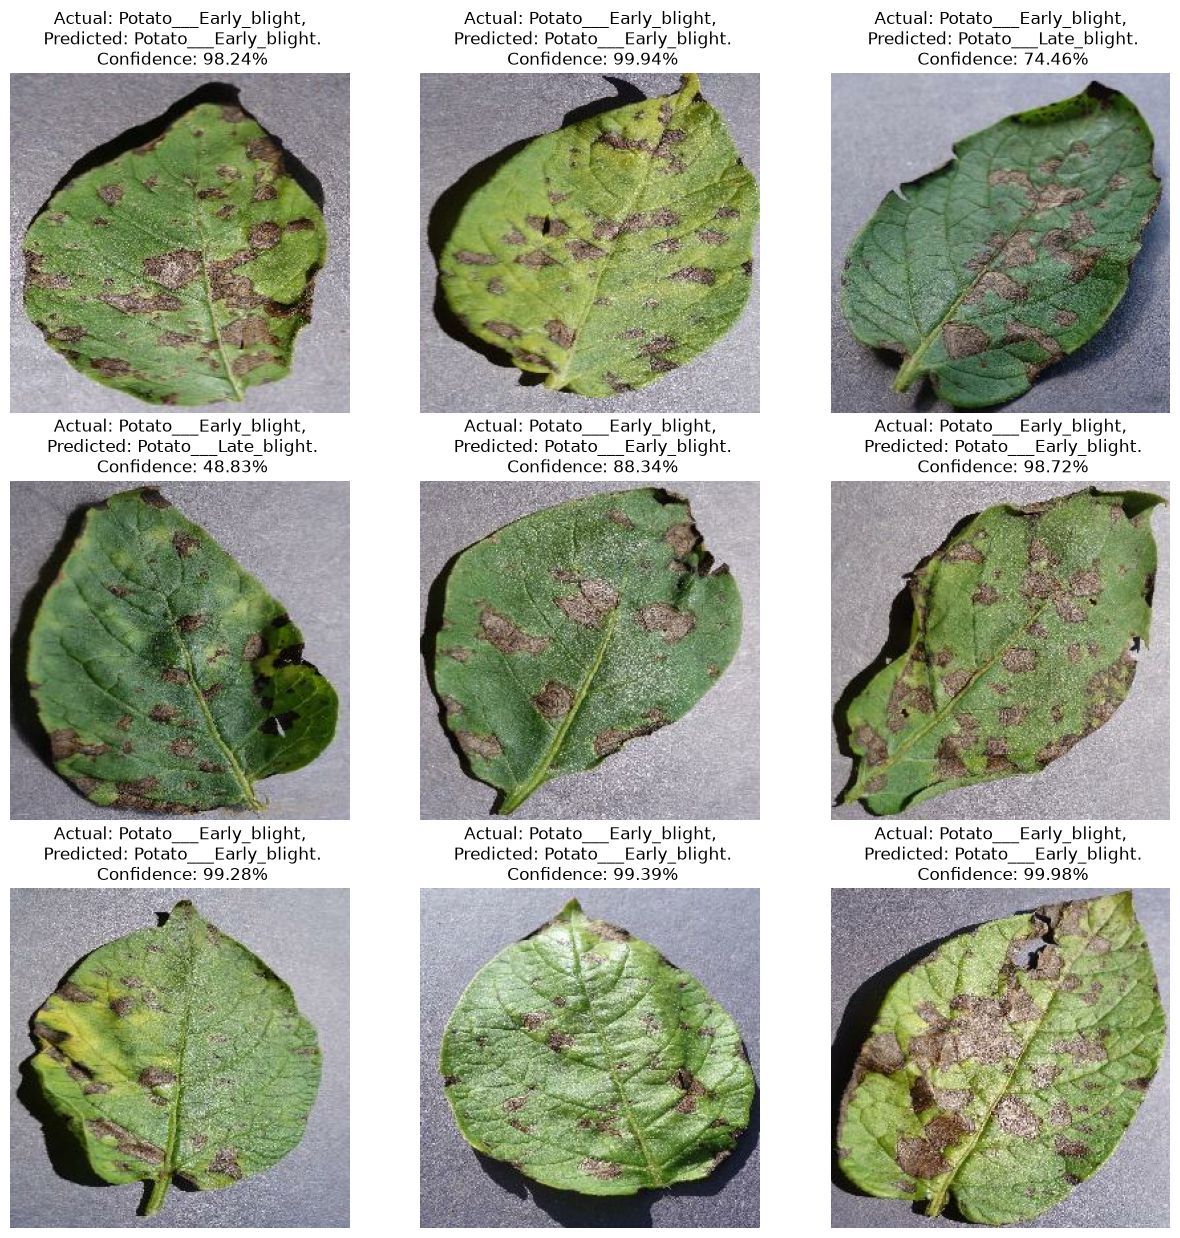

In [49]:
plt.figure(figsize=(15, 15))
for images_batch, labels_batch in test_ds.take(2):
  for i in range(min(9, len(images_batch))):
    ax = plt.subplot(3, 3, i + 1)
    plt.imshow(images_batch[i].numpy().astype("uint8"))

    predicted_class, confidence = predict(model, images_batch[i])
    actual_class = class_names[labels_batch[i]]

    plt.title(f"Actual: {actual_class},\n Predicted: {predicted_class}.\n Confidence: {confidence}%")

    plt.axis("off")

In [50]:
MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
model.save(MODEL_PATH)
print(f"Saved model to {MODEL_PATH.resolve()}")


Saved model to E:\projects\DL PROJET\Models\1.keras
